<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Imbalanced Data 

---

### About
Understand the challenges of imbalanced data and apply techniques to address class imbalance in data sets.  This notebook uses the [`imbalanced-learn`](https://imbalanced-learn.org/stable/) library and the examples within it extensively.

`imbalanced-learn` library: https://imbalanced-learn.org/stable/

### Learning Objectives
- Describe when imbalanced data is a problem
- Identify methods for handling imbalanced data and appropriately evaluating performance
- Apply the [`imbalanced-learn`](https://imbalanced-learn.org/stable/index.html) library to oversample minority classes
- Apply the [`imbalanced-learn`](https://imbalanced-learn.org/stable/index.html) library to create synthetic minority class observations

### Notebook Guide

- Imports, and install `imbalanced-learn` package, if needed
- Data SetUp
- Model Setup (Logistic Regression)
- Option 1: Oversample the minority class
- Option 2: Create synthetic data points similar to the minority class
    - SMOTE
    - ADASYN
- Option 3: Overweight minority class importance in algorithms
- Option 4: Change the class cutoff threshold

---
### Metrics

- ALWAYS think about your evaluation metrics AND how a null baseline model performs compared to your model. 
- Check out the confusion matrix.
- Consider using balanced accuracy if you care about all outcome classes equally.



# Imports, and install `imbalanced-learn` package if needed

In [67]:
# % pip install -U imbalanced-learn

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (balanced_accuracy_score, ConfusionMatrixDisplay, 
                            recall_score, precision_score, f1_score)

from sklearn.datasets import fetch_openml

from imblearn.datasets import make_imbalance

We'll use an example data set used within the User Guide in the docs (see [here](https://imbalanced-learn.org/stable/common_pitfalls.html)): the adult census dataset. As with the User Guide, for the sake of simplicity we will only use the numerical features. Also, we will make the dataset more imbalanced.

In [69]:
# Option 1: fetch the data from only, select only the numerical features, and make the data imbalanced.  If you do it this way, skip to the 
# next section from here (Data Setup)

# X, y = fetch_openml(data_id=1119, as_frame=True, return_X_y=True, parser='auto')
# X = X.select_dtypes(include="number")
# X, y = make_imbalance(X, y, sampling_strategy={">50K": 300}, random_state=1) # a convenience method for making imbalanced data

## Data Dictionary

The census survey collects demographic and employment information about individuals to understand the characteristics of the population.

| Column | Description |
|---|---|
| `age` | Age of the person in years. |
| `fnlwgt` | Final census weight. It represents how many people in the population this record is estimated to represent. |
| `education-num` | Numerical representation of education level, generally corresponding to years/level of education. |
| `capital-gain` | Income received from capital gains. A value of `0` means no reported capital gain. |
| `capital-loss` | Loss reported from investments/capital assets. A value of `0` means no reported capital loss. |
| `hours-per-week` | Number of hours the person usually works per week. |
| `class` | Target variable indicating income class: `<=50K` or `>50K` per year. |

In [70]:
# Option 2: read in the data (note: this data has already been made more imbalanced)

claims = pd.read_csv('../data/imbl_data.csv', index_col=0)

In [71]:
claims.head()

,age,fnlwgt:,education-num:,capital-gain:,capital-loss:,hours-per-week:,class
0,39,77516,13,2174,0,40,<=50K
1,50,83311,13,0,0,13,<=50K
2,38,215646,9,0,0,40,<=50K
3,53,234721,7,0,0,40,<=50K
4,28,338409,13,0,0,40,<=50K


In [72]:
claims.info()

<class 'pandas.DataFrame'>
Index: 25020 entries, 0 to 27605
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              25020 non-null  int64
 1   fnlwgt:          25020 non-null  int64
 2   education-num:   25020 non-null  int64
 3   capital-gain:    25020 non-null  int64
 4   capital-loss:    25020 non-null  int64
 5   hours-per-week:  25020 non-null  int64
 6   class            25020 non-null  str  
dtypes: int64(6), str(1)
memory usage: 1.5 MB


In [73]:
# Check target balance
claims['class'].value_counts()

class
<=50K    24720
>50K       300
Name: count, dtype: int64

In [74]:
# Separate X & y
X = claims.drop(columns=['class'])
y = claims['class']

In [75]:
# Select only the numerical features
#X = X.select_dtypes(include= 'number')


# Data Setup 

In [76]:
# train test split 
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=6) 

In [77]:
# scale the data
scaler = StandardScaler()

X_train_ss = scaler.fit_transform(X_train)
X_test_ss = scaler.transform(X_test)

X_train_ss

array([[-0.4988079 , -0.56397883,  1.38122267, -0.10895672, -0.17054284,
         0.49117598],
       [-0.78348555,  0.70658092,  0.15554241, -0.10895672, -0.17054284,
        -1.53258086],
       [-0.35646907, -1.45167243,  0.15554241, -0.10895672, -0.17054284,
         0.89592735],
       ...,
       [ 1.4939357 ,  0.65654308,  0.15554241, -0.10895672, -0.17054284,
        -1.53258086],
       [-0.28529965,  0.17534302,  1.38122267, -0.10895672, -0.17054284,
         0.08642461],
       [-0.07179141, -1.10406753, -0.25301768, -0.10895672, -0.17054284,
         1.30067871]], shape=(18765, 6))

# Model Setup (Logistic Regression)

In [78]:
# Train the model
logr = LogisticRegression()
logr.fit(X_train_ss, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [79]:
# Evaluate model
logr.score(X_test_ss, y_test)

0.9883293365307754

The accuracy looks very high.

## What metrics do we know?

Helper code provided to review common metrics:

### Balanced Accuracy

**Balanced accuracy** is the average of how well the model performs on each class.

For binary classification:

$$
\text{Balanced Accuracy} =
\frac{\text{Recall of positive class} + \text{Recall of negative class}}{2}
$$

The difference from normal accuracy is:

- **Accuracy** asks: “What proportion of all predictions were correct?”
- **Balanced** accuracy asks: “How well did I perform on each class, giving both classes equal importance?”

In [80]:
def evaluation(X_test, y_test, preds, model):
    
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
    
    b_acc = balanced_accuracy_score(y_test, preds)
    recall = recall_score(y_test, preds, pos_label = ">50K")
    prec = precision_score(y_test, preds, pos_label = ">50K")
    f1 = f1_score(y_test, preds, pos_label = ">50K")

    print(f'balanced_accuracy: {b_acc}')
    print(f'recall: {recall}')
    print(f'precision: {prec}')
    print(f'f1 score: {f1}')

    return {
        'balanced_accuracy': b_acc,
        'recall': recall,
        'precision': prec,
        'f1_score': f1
    }

balanced_accuracy: 0.5330906148867314
recall: 0.06666666666666667
precision: 0.625
f1 score: 0.12048192771084337


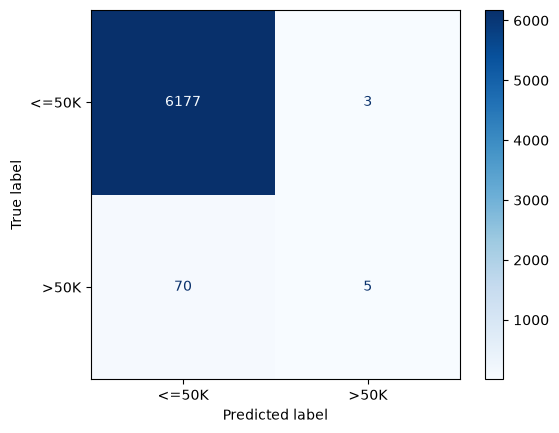

In [81]:
# setup and call the evaluation function defined above

scores = []
preds1 = logr.predict(X_test_ss)
scores.append(evaluation(X_test_ss, y_test, preds1, logr))

In [82]:
## What's inside scores ?
scores

[{'balanced_accuracy': 0.5330906148867314,
  'recall': 0.06666666666666667,
  'precision': 0.625,
  'f1_score': 0.12048192771084337}]

### Review Null Model, using the balanced accuracy score

In [83]:
??


IPython -- An enhanced Interactive Python

IPython offers a fully compatible replacement for the standard Python
interpreter, with convenient shell features, special commands, command
history mechanism and output results caching.

At your system command line, type 'ipython -h' to see the command line
options available. This document only describes interactive features.

GETTING HELP
------------

Within IPython you have various way to access help:

  ?         -> Introduction and overview of IPython's features (this screen).
  object?   -> Details about 'object'.
  object??  -> More detailed, verbose information about 'object'.
  %quickref -> Quick reference of all IPython specific syntax and magics.
  help      -> Access Python's own help system.

If you are in terminal IPython you can quit this screen by pressing `q`.


MAIN FEATURES
-------------

* Access to the standard Python help with object docstrings and the Python
  manuals. Simply type 'help' (no quotes) to invoke it.

* Ma

In [84]:
#null_preds = ??

In [85]:
#balanced_accuracy_score(y_test, null_preds)

Notice that we had very high accuracy with the first model but it's misleading due to the imbalanced classes. We can see that with the [balanced accuracy score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html) (also see [here](https://scikit-learn.org/stable/modules/model_evaluation.html#balanced-accuracy-score)), which is an average of the recall (sensitivity) obtained on each class.

$$
\text{Balanced Accuracy} = \frac{1}{N} \sum_{i=1}^{N} \frac{TP_i}{TP_i + FN_i}
$$

Let's correct for this!

---
# Option 1: Oversample the minority class


**Oversampling** is a data preprocessing technique designed to fix this problem by artificially increasing the number of samples in the minority class until it matches the scale of the majority class.

The goal is to give the minority class **more influence during model training**.

### ⚠️ A Critical Note

**Never oversample the entire dataset before splitting their data.**

If you oversample your data before running a train-test split, duplicated rows will leak into both your training and testing sets. This causes severe **Data Leakage**, resulting in perfect test scores in your model that will completely crash when deployed in production.

### ⚠️ Another Critical Note

**The Catch:** While it fixes the size imbalance, it introduces no new statistical information. It simply forces the model to read the exact same data rows multiple times, which drastically increases the risk of **overfitting** to those specific points.

In [86]:
from imblearn.over_sampling import RandomOverSampler

In [87]:
# Instantiate Balancer

# sampling_strategy controls the ratio of minority to majority samples after oversampling.
# For example:
#   - sampling_strategy=1.0: Minority class is oversampled to match the majority (completely balanced).
#   - sampling_strategy=0.75: Minority class is oversampled to reach 75% the size of the majority class.

ros = RandomOverSampler(sampling_strategy= 0.7)

In [88]:
# Oversample ONLY the training data
X_train_over, y_train_over = ros.fit_resample(X_train_ss, y_train)

In [89]:
print("Before oversampling:")
print(y_train.value_counts())

print("\nAfter oversampling:")
print(y_train_over.value_counts())

Before oversampling:
class
<=50K    18540
>50K       225
Name: count, dtype: int64

After oversampling:
class
<=50K    18540
>50K     12978
Name: count, dtype: int64


In [90]:
# Train using the oversampled training data

lr_over = LogisticRegression(max_iter=1000)
lr_over.fit(X_train_over, y_train_over)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [91]:
# Evaluate the model

y_pred_over = lr_over.predict(X_test_ss)

balanced_accuracy: 0.7135760517799353
recall: 0.56
precision: 0.04866743916570104
f1 score: 0.08955223880597014


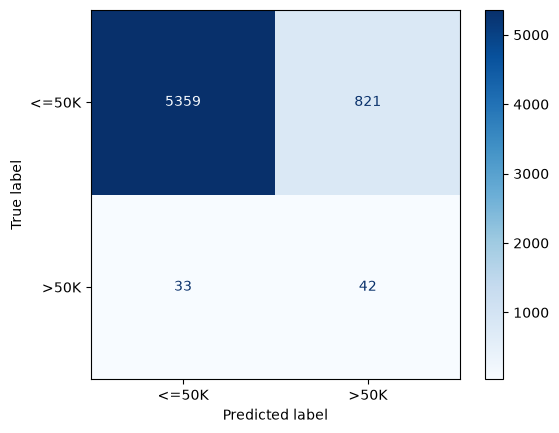

In [92]:
scores.append( evaluation(X_test_ss, y_test, y_pred_over, lr_over) )

In [93]:
# Compare both models
pd.DataFrame(scores, index=['logr', 'RandomOverSampler'])

,balanced_accuracy,recall,precision,f1_score
logr,0.533091,0.066667,0.625000,0.120482
RandomOverSampler,0.713576,0.560000,0.048667,0.089552


---
# Option 2: Create synthetic data points similar to the minority class

**SMOTE** (Synthetic Minority Over-sampling Technique) - make some fake data of the minority class. 

Interpolates to create more minority class observations.

**How it works:** 
- It selects a minority sample
- Finds its nearest neighbors in the feature space
- Draws a straight mathematical line between them
- Places a brand new data point somewhere along that line. 

_Check the demonstration in [this link](https://samuel-book.github.io/samuel-2/synthetic_data_demo/02a_synthetic_samuel1_data%20_SMOTE.html?utm_source=chatgpt.com)_


![scatterplots with SMOTE and ADASYN](../assets/smote-docs.png) From the docs: https://imbalanced-learn.org/stable/over_sampling.html#naive-random-over-sampling

### **Key SMOTE hyperparameter** 

####  `k_neighbors` (default=5)
This parameter defines the **neighborhood size** for the underlying K-Nearest Neighbors algorithm used to construct synthetic points.

* **Impact of Tuning:**
  * **Lowering k (e.g., `k_neighbors=2`):** Restricts generation to very tight, highly localized clusters. Use this if your minority class has small isolated subgroups.
  * **Raising k (e.g., `k_neighbors=10`):** Broadens the generation space, creating highly diverse synthetic samples. However, if k is too large, SMOTE might bridge distant outliers, accidentally creating synthetic points in regions belonging to the majority class (introducing noise).


In [94]:
from imblearn.over_sampling import SMOTE

In [95]:
# Instantiate the balancer and resample your data

smote = SMOTE(k_neighbors=5, random_state=6, sampling_strategy=0.7)

X_train_smote, y_train_smote = smote.fit_resample(X_train_ss, y_train)

In [96]:
# Check target balance

y_train_smote.value_counts()

class
<=50K    18540
>50K     12978
Name: count, dtype: int64

In [97]:
# Train a new model

lr_smot = LogisticRegression()
lr_smot.fit(X_train_smote, y_train_smote)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

### TRY IT!

Check the performance 

balanced_accuracy: 0.7174919093851133
recall: 0.5733333333333334
precision: 0.04788418708240535
f1 score: 0.08838643371017471


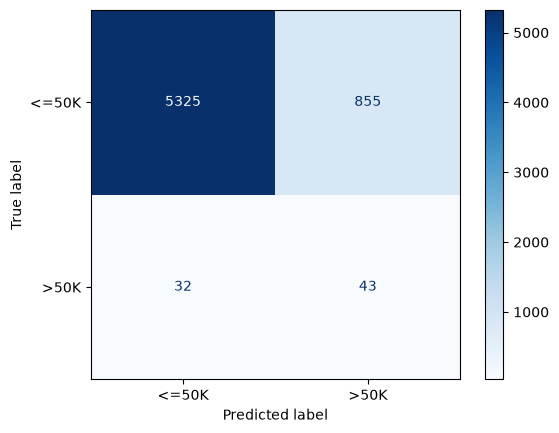

In [98]:
y_pred_smot = lr_smot.predict(X_test_ss)
scores.append(evaluation(X_test_ss, y_test, y_pred_smot, lr_smot))

In [99]:
pd.DataFrame(scores, index=['logr', 'RandomOverSampler', 'SMOTE'])


,balanced_accuracy,recall,precision,f1_score
logr,0.533091,0.066667,0.625000,0.120482
RandomOverSampler,0.713576,0.560000,0.048667,0.089552
SMOTE,0.717492,0.573333,0.047884,0.088386


### Effects
By training on different data you can change the decision function.

- If we change the training data using SMOTE or ADASYN, the model learns different parameters, so its decision boundaries can move.

<img src='../assets/decision-function.png'>

**Source:** the docs

### STRETCH: ADASYN
#### Like SMOTE, but focus on the hard observations. Make more data points like them.

"ADASYN focuses on generating samples next to the original samples which are wrongly classified using a k-Nearest Neighbors classifier while the basic implementation of SMOTE will not make any distinction between easy and hard samples to be classified using the nearest neighbors rule." - the docs

In [100]:
from imblearn.over_sampling import ADASYN

balanced_accuracy: 0.7490614886731392
recall: 0.7466666666666667
precision: 0.035175879396984924
f1 score: 0.06718656268746251


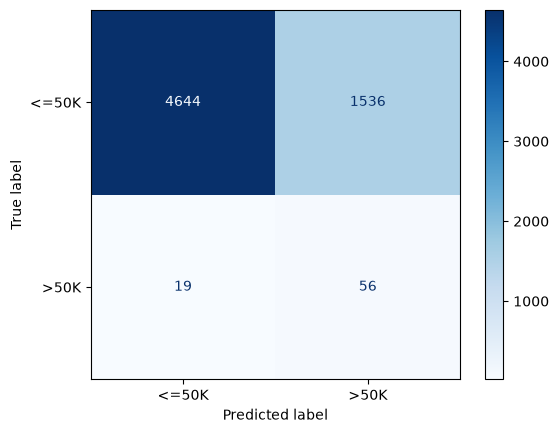

In [101]:

adasyn = ADASYN(random_state=34)

X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train_ss, y_train)

lr_adasyn = LogisticRegression()
lr_adasyn.fit(X_train_adasyn, y_train_adasyn)

y_pred_adasyn = lr_adasyn.predict(X_test_ss)
scores.append(evaluation(X_test_ss, y_test, y_pred_adasyn, lr_adasyn))

In [102]:
pd.DataFrame(scores, index=['logr', 'RandomOverSampler', 'SMOTE', 'ADASYN'])

,balanced_accuracy,recall,precision,f1_score
logr,0.533091,0.066667,0.625000,0.120482
RandomOverSampler,0.713576,0.560000,0.048667,0.089552
SMOTE,0.717492,0.573333,0.047884,0.088386
ADASYN,0.749061,0.746667,0.035176,0.067187


### Handling Categorical Features 
 When the features are categorical or a mix of categorical and continuous you need to use special versions of SMOTE: ⚠️

- Use `SMOTENC` for mixed features (categorical and continuous).
- Use `SMOTEN` when you have all categorical features.

Review the examples in [the docs](https://imbalanced-learn.org/stable/over_sampling.html#smote-variants)

### SMOTE variations

There are several other SMOTE algorithms you can use. The ones you've seen above should be enough for most problems. If you want to try others, see the [docs](https://imbalanced-learn.org/stable/over_sampling.html#smote-variants).

---
# Option 3: Overweight minority class importance in algorithms

Some models, such as Logistic Regression, allow us to assign different **weights** to different classes during training.

Think of the class weight as:

> **How much does the model care if it gets this class wrong?**

A higher weight means that mistakes on that class contribute more strongly to the model's loss during training.

For an imbalanced dataset, we can give the minority class a higher weight so that the model pays more attention to mistakes made on that class.

`class_weight="balanced"` automatically gives **more weight to less frequent classes** and less weight to more frequent classes.

Class weighting can improve performance on the minority class, but it may also increase false positives.

In [103]:
lr_weighted = LogisticRegression( class_weight='balanced')

lr_weighted.fit(X_train_ss, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the fol

balanced_accuracy: 0.7407281553398058
recall: 0.68
precision: 0.03990610328638498
f1 score: 0.07538802660753881


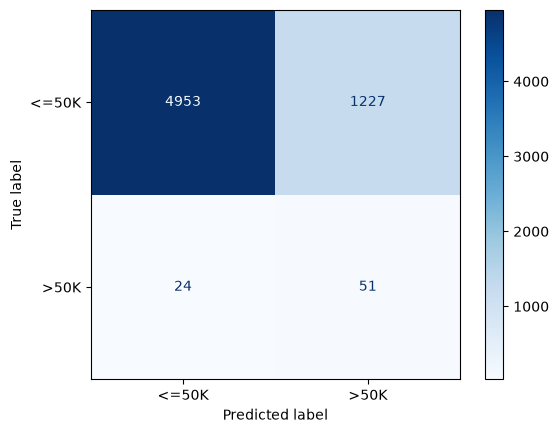

In [104]:
scores.append(evaluation(X_test_ss, y_test, lr_weighted.predict(X_test_ss), lr_weighted))

In [105]:
pd.DataFrame(scores, index=['logr', 'RandomOverSampler', 'SMOTE', 'ADASYN', 'WeightedLogr'])

,balanced_accuracy,recall,precision,f1_score
logr,0.533091,0.066667,0.625000,0.120482
RandomOverSampler,0.713576,0.560000,0.048667,0.089552
SMOTE,0.717492,0.573333,0.047884,0.088386
ADASYN,0.749061,0.746667,0.035176,0.067187
WeightedLogr,0.740728,0.680000,0.039906,0.075388


To learn more about this option, check out [this Machine Learning Mastery article](https://machinelearningmastery.com/cost-sensitive-logistic-regression/).

--- 
## Summary

Much classification data is imbalanced. You've seen how to deal with it to improve model performance while not overstating your model's likely generalizability.

### Overall approach

- Carefully consider your metrics. 
- Make a baseline null model.
- With a task like image classification with a neural net, you just need enough minority samples. Data augmentation can be helpful. The imbalance doesn't matter that much.
- Getting more data is often helpful. 😉

---
### Techniques to improve model performance on minority class ⭐️⭐️⭐️
1. Oversample the minority class
1. Create syntethic data like the minority class (e.g. use SMOTE)
1. Overweight the minority class importance in your algorithm

### Imbalanced learn

The `imbalanced-learn` library can help you by providing a `make_pipeline` that keeps your test set safe.

You can use `imbalanced-learn` to train on a random oversampling of your minority class observations. It can also help you create synthetic data with SMOTE of some variation or ADASYN. 

Don't forget to use `imbalanced-learn`'s pipeline so that the training data has the observations you need and the test set is left untouched.